### 向量艺术-LangChain的嵌入实现
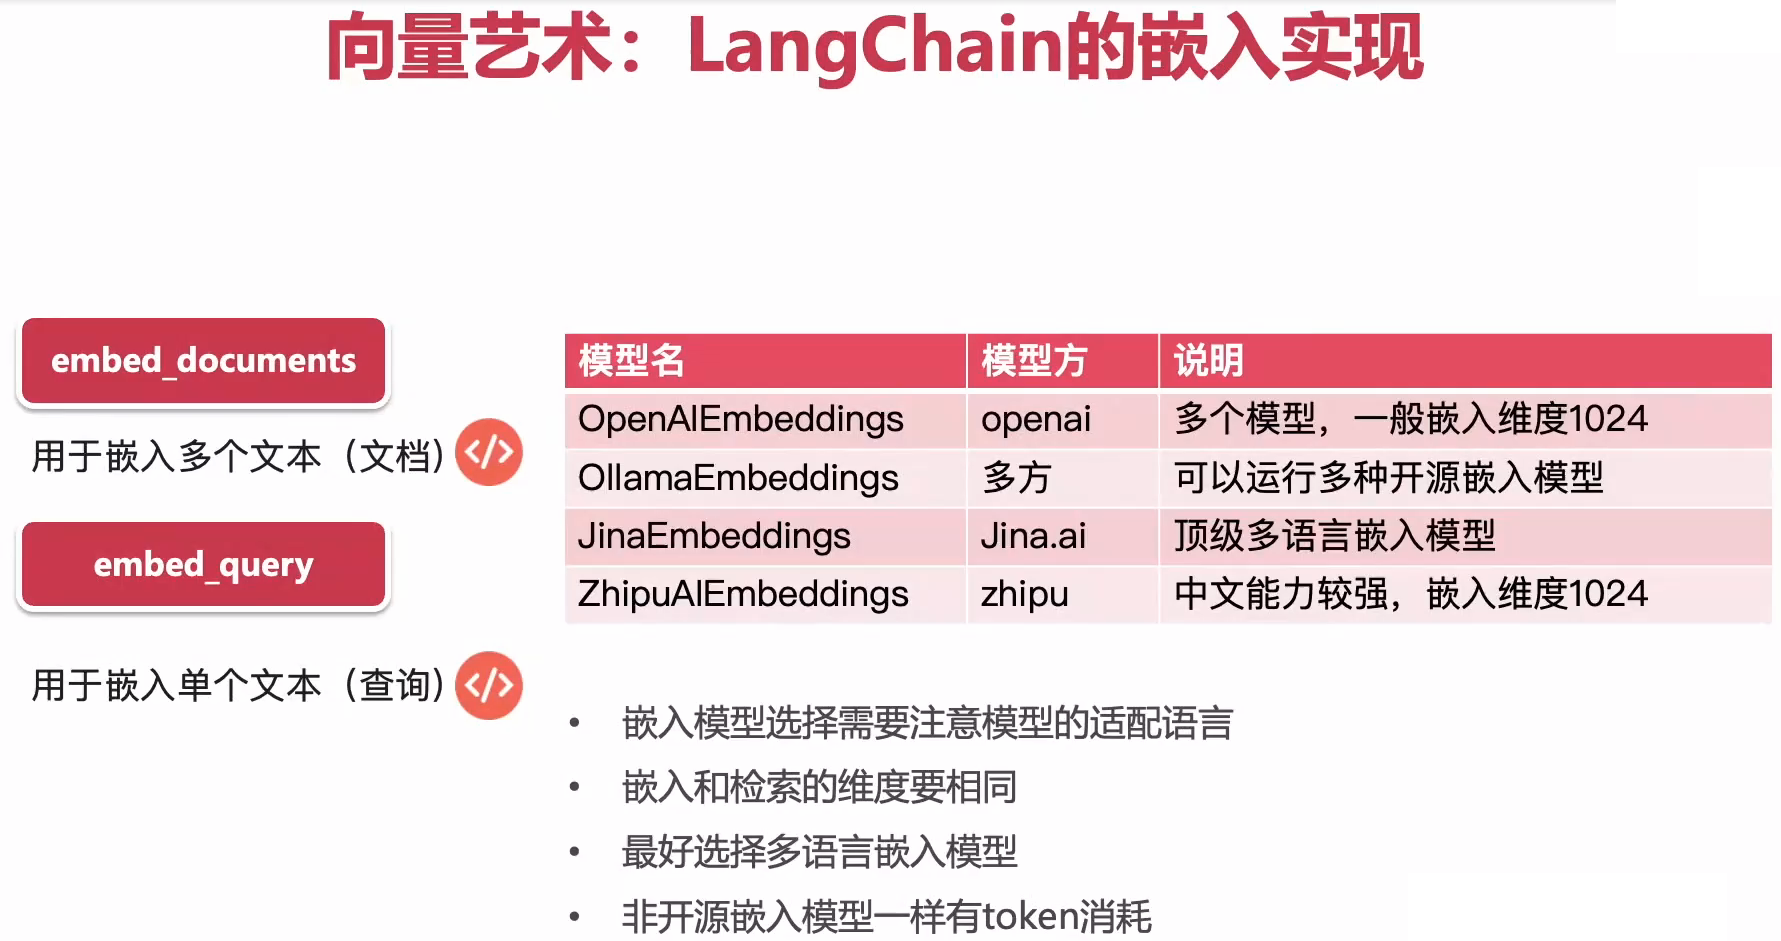

### 嵌入模型
---
* enbed_documents
* embed_query
* 嵌入缓存
* 使用国产的嵌入模型


### 向量艺术：嵌入模型
- 将文本转换为数字向量表示
- 使用简单的数学运算来比较嵌入向量  
  
  
***
- 嵌入模型是向量化的核心
- 市场上有海量的嵌入模型
- LangChain提供了标准接口
- 嵌入过程本质是一组高维坐标
- 常见的相似性算法有:
- 余弦相似度: 测量两个向量之间角度的余
- 欧几里得距离: 测量两点之间的直线距离
- 点积: 测量一个向量到另一个向量的投影

### 向量艺术：LangChain的嵌入实现

- embed_documents：用于嵌入多个文本(文档)  
- embed_query：用于嵌入单个文本(查询)
- 嵌入缓存
- 使用国产的嵌入模型

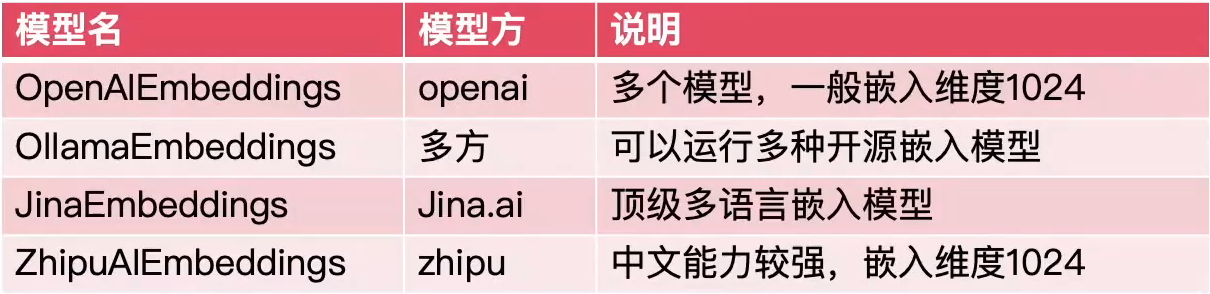
- 嵌入模型选择需要注意模型的适配语言
- 嵌入和检索的维度要相同
- 最好选择多语言嵌入模型
- 非开源嵌入模型一样有token消耗

### enbed_documents
---

In [24]:
from langchain_openai import OpenAIEmbeddings
from dotenv import load_dotenv

import os

load_dotenv()

embeddings_model = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)
embeddings = embeddings_model.embed_documents(
    [
        "Hi there!",
        "Oh, hello!",
        "What's your name?",
        "My friends call me World",
        "Hello World!"
    ]
)

len(embeddings), len(embeddings[0])

print(f"\n✅ 成功！共生成 {len(embeddings)} 个向量。")
print(f"每个向量的维度是: {len(embeddings[0])} 维 (text-embedding-v3 默认 1024 维)")


✅ 成功！共生成 5 个向量。
每个向量的维度是: 4096 维 (text-embedding-v3 默认 1024 维)


### embed_query
---

In [6]:
query_embedding = embeddings_model.embed_query("What is the meaning of life?")
print(query_embedding)

[0.007508592680096626, -0.002191348932683468, 0.026553992182016373, -0.006284015253186226, -0.010247779078781605, 0.004640503320842981, 0.011794612742960453, 0.0031581204384565353, 0.005317243747413158, 0.0031903462950140238, -0.018819820135831833, 0.000149043946294114, 0.014308218844234943, 0.010763389989733696, 0.0217845868319273, 0.01920652762055397, 0.005381694994866848, -0.004962760955095291, 0.0030775561463087797, 0.03325694054365158, 0.008024203591048717, -0.013985961675643921, 0.04382697865366936, 0.012761385180056095, 0.013212544843554497, 0.015339442528784275, -0.0030131046660244465, -0.0018690916476771235, 0.006960755214095116, 0.009087652899324894, -0.016306214034557343, 0.011407904326915741, 0.024749351665377617, 0.037897445261478424, -0.017659693956375122, 0.011536807753145695, 0.0031581204384565353, -0.0193354319781065, 0.010698938742280006, -0.017144082114100456, 0.006477369461208582, 0.0177885964512825, -0.010376681573688984, -0.012310224585235119, 0.006251789629459381

### 缓存嵌入结果
---

In [33]:
! pip install --upgrade --quiet langchain-openai faiss-cpu

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain 0.3.7 requires langchain-core<0.4.0,>=0.3.15, but you have langchain-core 1.7.6 which is incompatible.
langchain 0.3.7 requires langsmith<0.2.0,>=0.1.17, but you have langsmith 0.14.17 which is incompatible.
langchain-chroma 1.1.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
langchain-classic 1.0.8 requires langchain-text-splitters<2.0.0,>=1.1.2, but you have langchain-text-splitters 0.3.8 which is incompatible.
langchain-community 0.3.7 requires langchain-core<0.4.0,>=0.3.17, but you have langchain-core 1.7.6 which is incompatible.
langchain-community 0.3.7 requires langsmith<0.2.0,>=0.1.125, but you have langsmith 0.14.17 which is incom

In [49]:
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document

# 1. 初始化 Embeddings 模型
embeddings = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)

docs = [
    Document(page_content="什么是人工智能？", metadata={"source": "web"}),
    Document(page_content="LangChain 1.x 有什么新特性？", metadata={"source": "docs"})
]

# 🟢 首次运行：计算向量并保存到本地磁盘
print("首次运行：正在计算向量并保存...")
db = FAISS.from_documents(docs, embeddings)
db.save_local("./faiss_cache_dir")  # 将向量和数据保存到本地文件夹
print("✅ 首次计算并保存完成！\n")


# 🔵 后续运行：直接从本地加载（完全不调用 API）
print("后续运行：正在从本地缓存加载...")
# 注意：1.x 版本中 load_local 必须加上 allow_dangerous_deserialization=True 参数
db_loaded = FAISS.load_local(
    "./faiss_cache_dir", 
    embeddings, 
    allow_dangerous_deserialization=True
)

# 测试检索
results = db_loaded.similarity_search("LangChain 新特性", k=1)
print(f"✅ 加载完成！检索结果: {results[0].page_content}")

首次运行：正在计算向量并保存...
✅ 首次计算并保存完成！

后续运行：正在从本地缓存加载...
✅ 加载完成！检索结果: LangChain 1.x 有什么新特性？


In [46]:
import os
from dotenv import load_dotenv
from langchain_community.cache import SQLiteCache
from langchain_core.globals import set_llm_cache
from langchain_openai import OpenAIEmbeddings

# 1. 加载 .env 文件中的环境变量
load_dotenv()

# 2. 开启全局 SQLite 缓存
set_llm_cache(SQLiteCache(database_path=".langchain_global_cache.db"))

embeddings = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)

# ================= 测试缓存效果 =================
docs = ["什么是人工智能？", "LangChain 是什么？"]

print("第一次生成（会调用 API，并自动存入本地 SQLite 缓存）...")
vectors1 = embeddings.embed_documents(docs)
print(f"✅ 获取到 {len(vectors1)} 个向量，维度为 {len(vectors1[0])}\n")

print("第二次生成（直接从本地 SQLite 读取，不再调用 API，速度极快且免费）...")
vectors2 = embeddings.embed_documents(docs)
print("✅ 缓存读取完成！")

第一次生成（会调用 API，并自动存入本地 SQLite 缓存）...
✅ 获取到 2 个向量，维度为 4096

第二次生成（直接从本地 SQLite 读取，不再调用 API，速度极快且免费）...
✅ 缓存读取完成！


In [45]:
import os
import json
import hashlib
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings

load_dotenv()

# 1. 初始化底层 Embedding 模型
underlying_embeddings = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)

# 2. 自定义文件缓存类（替代 CacheBackedEmbeddings）
class FileCachedEmbeddings:
    def __init__(self, embeddings, cache_dir="./cache/embeddings"):
        self.embeddings = embeddings
        self.cache_dir = cache_dir
        os.makedirs(self.cache_dir, exist_ok=True)
    
    def _get_cache_key(self, text):
        """用文本的 MD5 作为缓存文件名"""
        return hashlib.md5(text.encode('utf-8')).hexdigest() + ".json"
    
    def _get_cache_path(self, text):
        return os.path.join(self.cache_dir, self._get_cache_key(text))
    
    def embed_documents(self, texts):
        """带缓存的批量向量化"""
        results = []
        texts_to_embed = []  # 需要调用 API 的文本
        indices_to_embed = []  # 对应的索引
        
        # 第一步：检查缓存
        for i, text in enumerate(texts):
            cache_path = self._get_cache_path(text)
            if os.path.exists(cache_path):
                with open(cache_path, 'r') as f:
                    results.append(json.load(f))
            else:
                results.append(None)  # 占位
                texts_to_embed.append(text)
                indices_to_embed.append(i)
        
        # 第二步：对没有缓存的文本调用 API
        if texts_to_embed:
            print(f"  → 缓存未命中 {len(texts_to_embed)} 条，调用 API...")
            new_vectors = self.embeddings.embed_documents(texts_to_embed)
            
            # 第三步：写入缓存并填充结果
            for idx, text, vector in zip(indices_to_embed, texts_to_embed, new_vectors):
                cache_path = self._get_cache_path(text)
                with open(cache_path, 'w') as f:
                    json.dump(vector, f)
                results[idx] = vector
        else:
            print(f"  → 全部 {len(texts)} 条命中缓存，无需调用 API！")
        
        return results
    
    def embed_query(self, text):
        """单条文本向量化"""
        return self.embed_documents([text])[0]

# 3. 创建带缓存的 Embedding
cached_embedder = FileCachedEmbeddings(underlying_embeddings)

print("✅ 自定义缓存 Embedding 初始化成功！")

# ================= 测试效果 =================
texts = [
    "LangChain 是一个强大的框架。",
    "通义千问是阿里云的大模型。",
    "FAISS 是一个常用的向量数据库。"
]

print("\n第一次调用（会请求阿里云 API）...")
vectors_1 = cached_embedder.embed_documents(texts)
print(f"完成！生成了 {len(vectors_1)} 个向量，维度: {len(vectors_1[0])}")

print("\n第二次调用（直接读取本地缓存，不调 API）...")
vectors_2 = cached_embedder.embed_documents(texts)
print(f"完成！两次结果是否一致: {vectors_1 == vectors_2}")

✅ 自定义缓存 Embedding 初始化成功！

第一次调用（会请求阿里云 API）...
  → 全部 3 条命中缓存，无需调用 API！
完成！生成了 3 个向量，维度: 4096

第二次调用（直接读取本地缓存，不调 API）...
  → 全部 3 条命中缓存，无需调用 API！
完成！两次结果是否一致: True


In [55]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import CharacterTextSplitter

raw_documents = TextLoader("meow.txt").load()
text_splitter = CharacterTextSplitter(chunk_size=1000, chunk_overlap=0)
documents = text_splitter.split_documents(raw_documents)

创建向量存储

In [68]:
%%time
db = FAISS.from_documents(documents, cached_embedder)

`embedding_function` is expected to be an Embeddings object, support for passing in a function will soon be removed.


  → 全部 1 条命中缓存，无需调用 API！
CPU times: total: 0 ns
Wall time: 2.59 ms


再次创建将读取缓存，从而加快速度降低成本

In [69]:
%%time
db2 = FAISS.from_documents(documents, cached_embedder)

`embedding_function` is expected to be an Embeddings object, support for passing in a function will soon be removed.


  → 全部 1 条命中缓存，无需调用 API！
CPU times: total: 0 ns
Wall time: 2.39 ms
